# Aim of the notebook

Compare the uRNA of CosMx and Xenium data in mouse brain

# Load packages

In [1]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys
import seaborn as sns

parent_dir = os.path.abspath(os.path.join(os.getcwd(), "../../src/troutpy_reproducibility"))
# Add parent directory to sys.path
sys.path.append(parent_dir)

from batch_running import *

/home/sergio/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/sergio/.local/lib/python3.10/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [16]:
# Technology 1: Xenium
sdata1 = sd.read_zarr("/media/sergio/Meninges/troutpy/rois/xenium_msbrain_5k/data_processed.zarr")
results1 = sdata1["xrna_metadata"].var

# Technology 2: Xenium
sdata2 = sd.read_zarr("/media/sergio/Meninges/troutpy/rois/cosmx_mousebrain/data_processed.zarr")
results2 = sdata2["xrna_metadata"].var

In [17]:
results1_filt = results1[results1.index.isin(results2.index)]
results2_filt = results2[results2.index.isin(results1.index)]
results2 = results2_filt.loc[results1_filt.index]
merged_info = results1_filt.merge(results2_filt, left_index=True, right_index=True, suffixes=("_xenium", "_cosmx"), how="inner")

In [18]:
merged_info.fillna(0, inplace=True)

In [19]:
merged_info = merged_info[merged_info["logfoldratio_over_noise_xenium"] > 0]
merged_info = merged_info[merged_info["logfoldratio_over_noise_cosmx"] > 0]

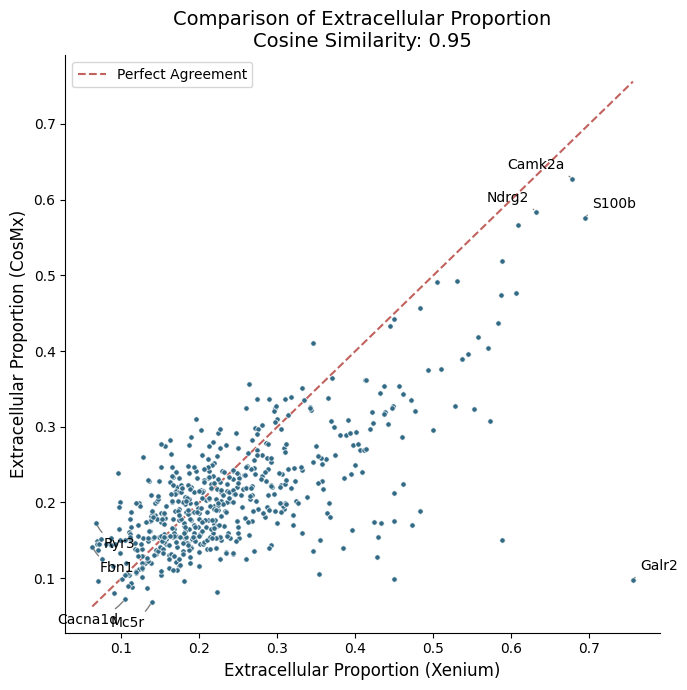

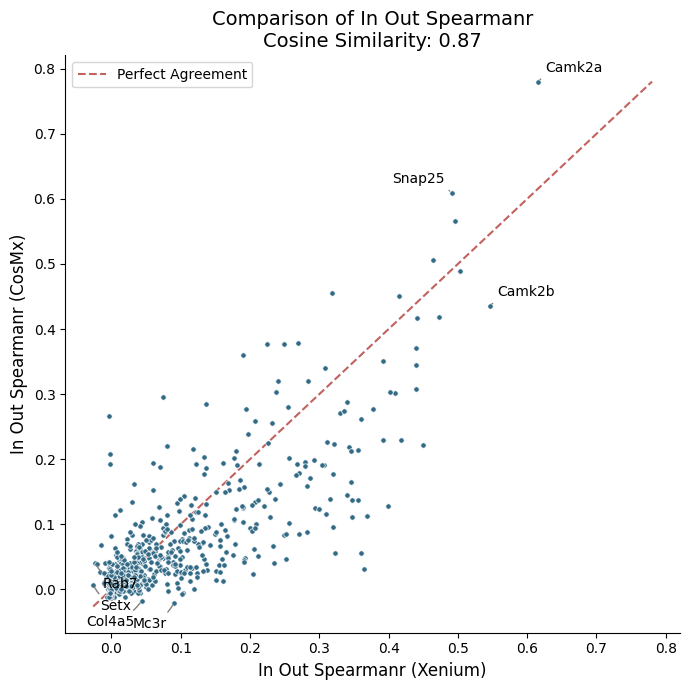

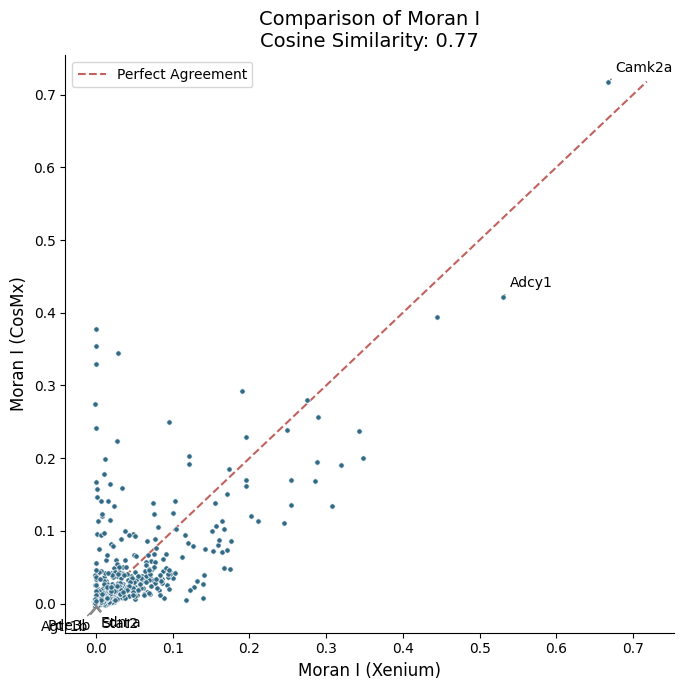

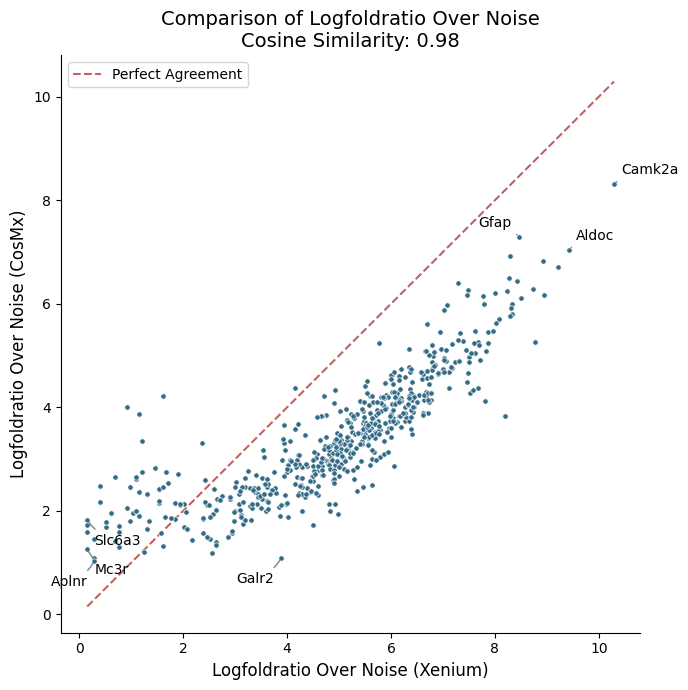

In [35]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib
import os

# Set font type for PDF and PostScript files
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

# Define the saving path for the figures
saving_path = '/media/sergio/Meninges/troutpy/figures'

# Create the directory if it doesn't exist
if not os.path.exists(saving_path):
    os.makedirs(saving_path)
    print(f"Created directory: {saving_path}")

metrics = ["extracellular_proportion", "in_out_spearmanR", "moran_I", "logfoldratio_over_noise"]
num_genes_to_annotate = 2 # Number of top/bottom genes to annotate per axis

for metric in metrics:
    fig, ax = plt.subplots(figsize=(7, 7)) # Slightly increased figure size for more annotations

    # Scatter Plot - Removed alpha for no transparency
    ax.scatter(
        merged_info[metric + "_xenium"],
        merged_info[metric + "_cosmx"],
        s=15,
        color="#336B87",  # Darker blue for scatter points
        edgecolors='w',
        linewidths=0.5,
        zorder=2 # Ensure scatter points are above the grid (if any)
    )

    # Labels and Title
    ax.set_xlabel(f"{metric.replace('_', ' ').title()} (Xenium)", fontsize=12)
    ax.set_ylabel(f"{metric.replace('_', ' ').title()} (CosMx)", fontsize=12)

    # Calculate Cosine Similarity
    vec1 = merged_info.loc[:, metric + "_xenium"].values.reshape(1, -1)
    vec2 = merged_info.loc[:, metric + "_cosmx"].values.reshape(1, -1)
    similarity = cosine_similarity(vec1, vec2)[0][0]

    # Title with Cosine Similarity
    ax.set_title(f"Comparison of {metric.replace('_', ' ').title()}\nCosine Similarity: {similarity:.2f}", fontsize=14)

    # Removed Grid and Simplified Axes
    ax.grid(False) # Explicitly turn off the grid

    # Remove top and right spines to leave only x and y axes
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    ax.tick_params(axis='x', labelsize=10) # Adjusted tick label font size
    ax.tick_params(axis='y', labelsize=10) # Adjusted tick label font size

    # Add a diagonal line for perfect agreement
    min_val = min(merged_info[metric + "_xenium"].min(), merged_info[metric + "_cosmx"].min())
    max_val = max(merged_info[metric + "_xenium"].max(), merged_info[metric + "_cosmx"].max())
    ax.plot([min_val, max_val], [min_val, max_val], color='#A8201A', linestyle='--', alpha=0.7, label='Perfect Agreement', zorder=1)

    # --- Annotate Top and Bottom Genes ---
    annotated_genes = set() # Keep track of genes already annotated to avoid duplicates

    # Annotate Top genes for Xenium axis
    top_xenium_genes = merged_info.sort_values(by=metric + "_xenium", ascending=False).head(num_genes_to_annotate)
    for gene_name, row in top_xenium_genes.iterrows(): # Iterate using gene_name from index
        if gene_name not in annotated_genes:
            ax.annotate(
                gene_name, # Use gene_name from index
                (row[metric + "_xenium"], row[metric + "_cosmx"]),
                textcoords="offset points",
                xytext=(5, 5), # Offset text slightly from the point
                ha='left', # Horizontal alignment
                va='bottom', # Vertical alignment
                fontsize=10,
                color='black',
                arrowprops=dict(arrowstyle='-', connectionstyle='arc3,rad=0.2', color='gray', lw=1)
            )
            annotated_genes.add(gene_name)

    # Annotate Bottom genes for Xenium axis
    bottom_xenium_genes = merged_info.sort_values(by=metric + "_xenium", ascending=True).head(num_genes_to_annotate)
    for gene_name, row in bottom_xenium_genes.iterrows(): # Iterate using gene_name from index
        if gene_name not in annotated_genes:
            ax.annotate(
                gene_name, # Use gene_name from index
                (row[metric + "_xenium"], row[metric + "_cosmx"]),
                textcoords="offset points",
                xytext=(5, -10), # Offset text slightly below the point
                ha='left',
                va='top', # Vertical alignment
                fontsize=10,
                color='black',
                arrowprops=dict(arrowstyle='-', connectionstyle='arc3,rad=-0.2', color='gray', lw=1)
            )
            annotated_genes.add(gene_name)

    # Annotate Top genes for CosMx axis
    top_cosmx_genes = merged_info.sort_values(by=metric + "_cosmx", ascending=False).head(num_genes_to_annotate)
    for gene_name, row in top_cosmx_genes.iterrows(): # Iterate using gene_name from index
        if gene_name not in annotated_genes:
            ax.annotate(
                gene_name, # Use gene_name from index
                (row[metric + "_xenium"], row[metric + "_cosmx"]),
                textcoords="offset points",
                xytext=(-5, 5), # Offset text slightly from the point
                ha='right', # Horizontal alignment
                va='bottom',
                fontsize=10,
                color='black',
                arrowprops=dict(arrowstyle='-', connectionstyle='arc3,rad=-0.2', color='gray', lw=1)
            )
            annotated_genes.add(gene_name)

    # Annotate Bottom genes for CosMx axis
    bottom_cosmx_genes = merged_info.sort_values(by=metric + "_cosmx", ascending=True).head(num_genes_to_annotate)
    for gene_name, row in bottom_cosmx_genes.iterrows(): # Iterate using gene_name from index
        if gene_name not in annotated_genes:
            ax.annotate(
                gene_name, # Use gene_name from index
                (row[metric + "_xenium"], row[metric + "_cosmx"]),
                textcoords="offset points",
                xytext=(-5, -10), # Offset text slightly below the point
                ha='right',
                va='top', # Vertical alignment
                fontsize=10,
                color='black',
                arrowprops=dict(arrowstyle='-', connectionstyle='arc3,rad=0.2', color='gray', lw=1)
            )
            annotated_genes.add(gene_name)
    # --- End Annotate Top and Bottom Genes ---

    ax.legend() # Ensure legend is shown after all plot elements

    plt.tight_layout()
    # Save the plot as a PDF
    plt.savefig(f"{saving_path}/{metric}_comparison_top_bottom_genes.pdf")
    plt.show()


In [30]:
merged_info

,count_xenium,logfoldratio_over_noise_xenium,control_probe_xenium,p_value_Poisson_xenium,intracellular_proportion_xenium,extracellular_proportion_xenium,logfoldratio_extracellular_xenium,moran_I_xenium,moran_pval_norm_xenium,moran_var_norm_xenium,...,intracellular_proportion_cosmx,extracellular_proportion_cosmx,logfoldratio_extracellular_cosmx,moran_I_cosmx,moran_pval_norm_cosmx,moran_var_norm_cosmx,moran_pval_norm_fdr_bh_cosmx,in_out_spearmanR_cosmx,in_out_pvalue_cosmx,proportion_of_colocalized_cosmx
Apc,10342.0,7.452209,False,0.000000e+00,0.490366,0.509634,-1.068986,0.201523,0.000000,0.000006,...,0.624280,0.375720,-0.423817,0.120013,0.000000e+00,0.000004,0.000000e+00,0.061925,4.535611e-11,0.178150
Dlg4,37440.0,8.738735,False,0.000000e+00,0.411617,0.588383,-1.387732,0.288727,0.000000,0.000006,...,0.481339,0.518661,-1.006250,0.256519,0.000000e+00,0.000004,0.000000e+00,0.378923,0.000000e+00,0.383381
Snrpn,8799.0,7.290634,False,0.000000e+00,0.702556,0.297444,-0.170949,0.120650,0.000000,0.000006,...,0.674633,0.325367,-0.202353,0.192061,0.000000e+00,0.000004,0.000000e+00,0.377035,0.000000e+00,0.389136
Dnm1,17856.0,7.998335,False,0.000000e+00,0.837886,0.162114,0.612139,0.196005,0.000000,0.000006,...,0.773178,0.226822,0.294776,0.161084,0.000000e+00,0.000004,0.000000e+00,0.451327,0.000000e+00,0.372919
Csf1,435.0,4.283587,False,0.000000e+00,0.873030,0.126970,0.897571,0.011257,0.000003,0.000006,...,0.898463,0.101537,1.248692,0.005442,2.760979e-03,0.000004,3.487553e-03,0.049019,1.877667e-07,0.083750
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Oprk1,28.0,1.540445,False,0.000000e+00,0.830303,0.169697,0.557330,-0.000868,0.369852,0.000006,...,0.852670,0.147330,0.824126,0.000725,3.525387e-01,0.000004,3.646952e-01,0.018850,4.518831e-02,0.085995
Gdnf,22.0,1.299283,False,0.000000e+00,0.738095,0.261905,0.005646,-0.000717,0.392703,0.000006,...,0.826396,0.173604,0.628727,0.003752,2.765061e-02,0.000004,3.269038e-02,0.009762,2.996667e-01,0.034343
Ntrk1,16.0,0.980829,False,2.291500e-13,0.757576,0.242424,0.108988,-0.000525,0.422469,0.000006,...,0.756824,0.243176,0.203774,0.354112,0.000000e+00,0.000004,0.000000e+00,0.027833,3.100145e-03,0.138702
Lpar2,13.0,0.773190,False,4.735725e-10,0.895161,0.104839,1.114135,-0.000402,0.441696,0.000006,...,0.895842,0.104158,1.220286,0.024952,0.000000e+00,0.000004,0.000000e+00,0.051683,3.916416e-08,0.042194


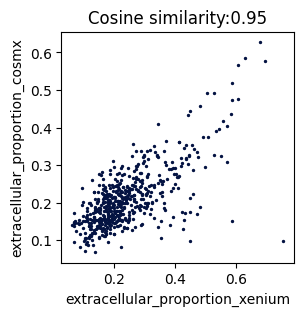

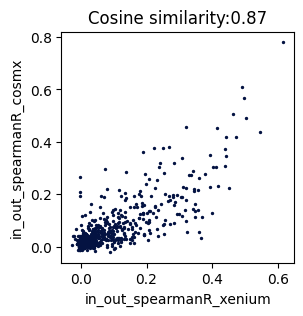

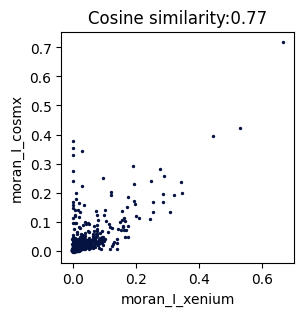

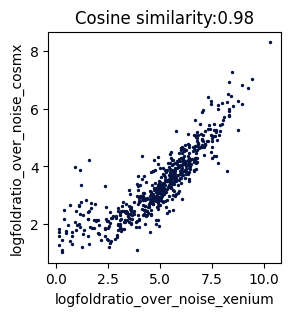

In [7]:
from sklearn.metrics.pairwise import cosine_similarity

metrics = ["extracellular_proportion", "in_out_spearmanR", "moran_I", "logfoldratio_over_noise"]
for metric in metrics:
    plt.figure(figsize=(3, 3))
    plt.scatter(merged_info[metric + "_xenium"], merged_info[metric + "_cosmx"], s=2, c="#041342")
    plt.xlabel(metric + "_xenium")
    plt.ylabel(metric + "_cosmx")
    # plt.title('pcc: '+str(np.round(cosine_similarity(merged_info[metric+'_xenium'],merged_info[metric+'_cosmx']),4)))
    # Extract the columns and reshape to 2D arrays
    vec1 = merged_info.loc[:, metric + "_xenium"].values.reshape(1, -1)
    vec2 = merged_info.loc[:, metric + "_cosmx"].values.reshape(1, -1)
    # Compute cosine similarity
    similarity = cosine_similarity(vec1, vec2)[0][0]
    plt.title("Cosine similarity:" + str(np.round(similarity, 2)))

In [80]:
merged_info.sort_values(by=["extracellular_proportion_xenium"], ascending=False)

,count_xenium,logfoldratio_over_noise_xenium,control_probe_xenium,p_value_Poisson_xenium,intracellular_proportion_xenium,extracellular_proportion_xenium,logfoldratio_extracellular_xenium,moran_I_xenium,moran_pval_norm_xenium,moran_var_norm_xenium,...,intracellular_proportion_cosmx,extracellular_proportion_cosmx,logfoldratio_extracellular_cosmx,moran_I_cosmx,moran_pval_norm_cosmx,moran_var_norm_cosmx,moran_pval_norm_fdr_bh_cosmx,in_out_spearmanR_cosmx,in_out_pvalue_cosmx,proportion_of_colocalized_cosmx
Galr2,759.0,-3.300608,False,0.0,0.283267,0.716733,-1.958851,0.045624,0.000000,0.000003,...,0.902167,0.097833,1.289965,0.029021,0.000000,0.000004,0.000000,0.021059,2.524933e-02,0.013889
S100b,15583.0,-0.278674,False,0.0,0.346596,0.653404,-1.664578,0.026998,0.000000,0.000003,...,0.423683,0.576317,-1.239241,0.049415,0.000000,0.000004,0.000000,0.094990,4.748650e-24,0.202133
Camk2a,466955.0,3.121379,False,0.0,0.364279,0.635721,-1.587379,0.637023,0.000000,0.000003,...,0.372494,0.627506,-1.453102,0.717944,0.000000,0.000004,0.000000,0.780224,0.000000e+00,0.782549
Ndrg2,165577.0,2.084582,False,0.0,0.395284,0.604716,-1.455693,0.140617,0.000000,0.000003,...,0.415839,0.584161,-1.271446,0.203392,0.000000,0.000004,0.000000,0.178471,1.898036e-81,0.491115
Gfap,74276.0,1.282934,False,0.0,0.406295,0.593705,-1.409841,0.446543,0.000000,0.000003,...,0.433500,0.566500,-1.199154,0.393795,0.000000,0.000004,0.000000,0.419160,0.000000e+00,0.609843
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Avpr2,131.0,-5.057412,False,0.0,0.923664,0.076336,1.462665,-0.000150,0.468660,0.000003,...,0.770736,0.229264,0.280903,-0.001283,0.260534,0.000004,0.275062,-0.002641,7.790619e-01,0.025105
Lepr,1083.0,-2.945119,False,0.0,0.925208,0.074792,1.484764,0.001167,0.244732,0.000003,...,0.806627,0.193373,0.496667,0.016988,0.000000,0.000004,0.000000,-0.002922,7.562284e-01,0.012698
Aplnr,269.0,-4.337898,False,0.0,0.929368,0.070632,1.546482,0.018775,0.000000,0.000003,...,0.854789,0.145211,0.841096,0.005377,0.003056,0.000004,0.003845,0.002836,7.631979e-01,0.029197
Crhr2,173.0,-4.779318,False,0.0,0.936416,0.063584,1.659161,-0.000173,0.463332,0.000003,...,0.740274,0.259726,0.115824,0.007661,0.000048,0.000004,0.000068,0.010980,2.433702e-01,0.017467


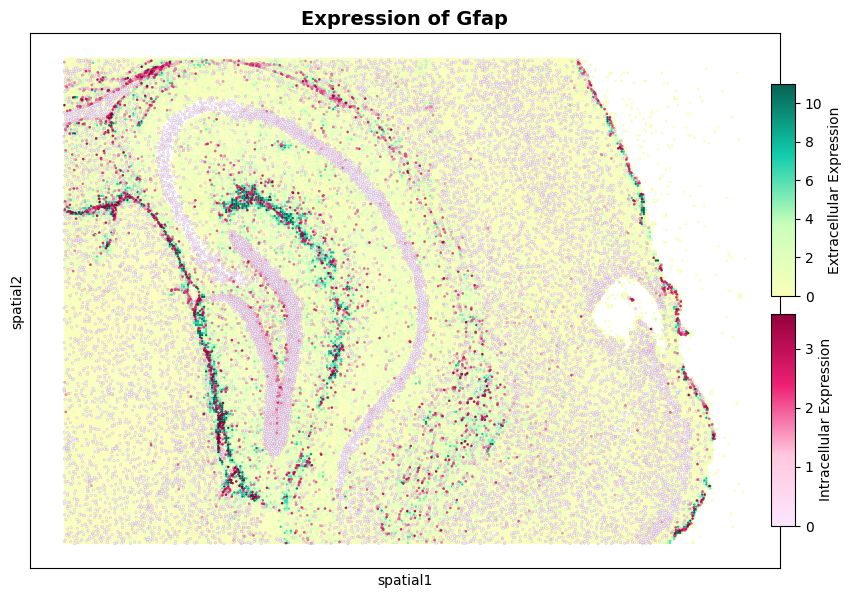

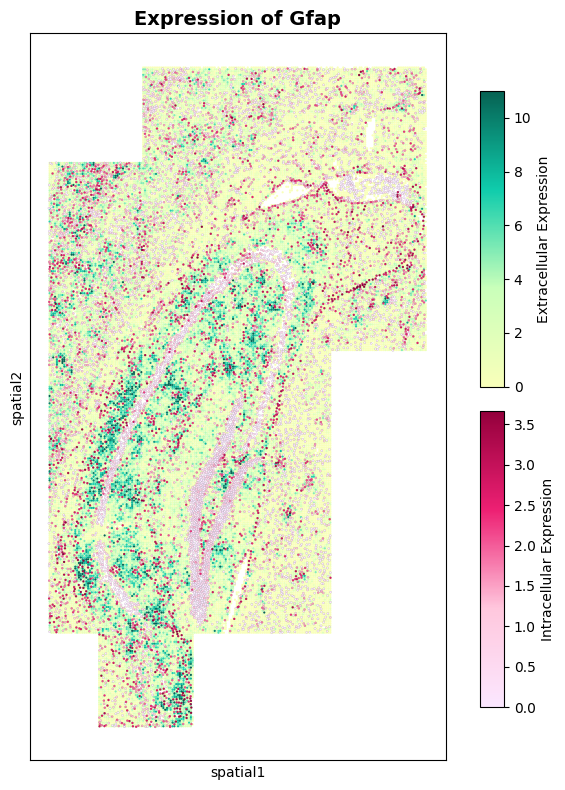

In [106]:
troutpy.pl.spatial_inout_expression(sdata1, "Gfap", spot_size_cells=12)
troutpy.pl.spatial_inout_expression(sdata2, "Gfap", spot_size_cells=12)

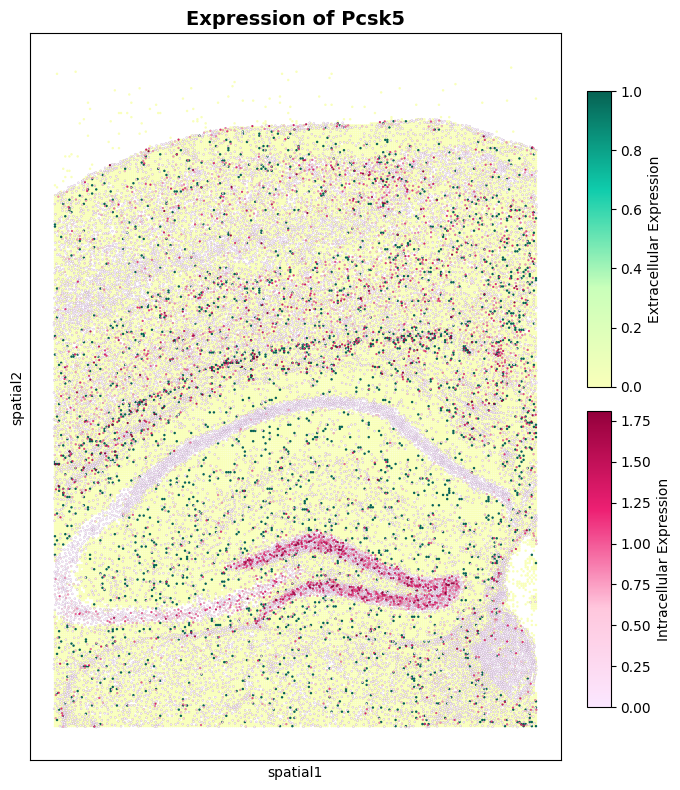

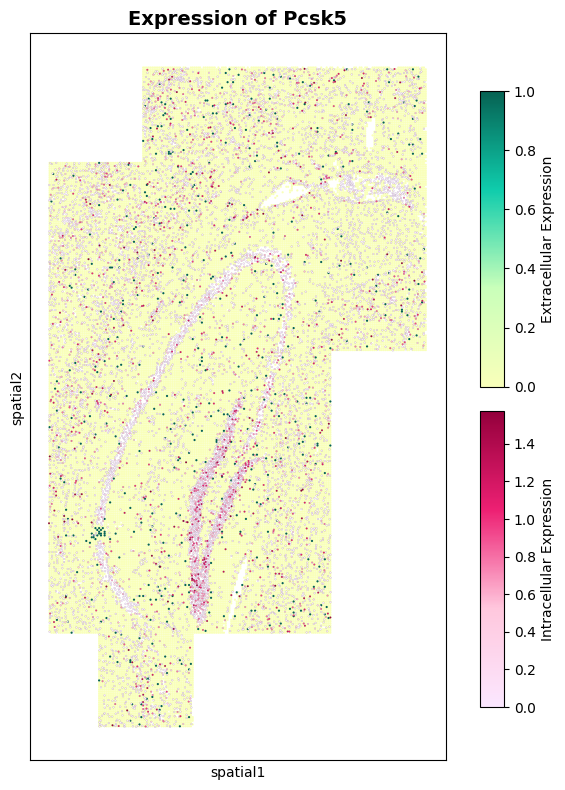

In [73]:
g2 = "Pcsk5"
troutpy.pl.spatial_inout_expression(sdata1, g2, spot_size_cells=10)
troutpy.pl.spatial_inout_expression(sdata2, g2, spot_size_cells=10)